# Lab 8a: When a straight line is not enough

How do we deal with linearly non-separable (even approximately) data? Here we introduce two new methods: **look at nearby points** (k nearest neighbors), and
**apply a nonlinear transformation** (kernels).

Run the cells and answer the short questions.

In [1]:
# PROVIDED
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

COLORS  = ['#2a78d6', '#eb6834']
MARKERS = ['o', '^']

def plot_boundary(model, X, y, ax, title=''):
    pad = 0.4
    g1 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300)
    g2 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300)
    GG1, GG2 = np.meshgrid(g1, g2)
    Z = model.predict(np.c_[GG1.ravel(), GG2.ravel()]).reshape(GG1.shape)

    ax.contourf(GG1, GG2, Z, levels=[-0.5, 0.5, 1.5], colors=COLORS, alpha=0.18)
    ax.contour(GG1, GG2, Z, levels=[0.5], colors='0.25', linewidths=1.5)
    for c in (0, 1):
        m = y == c
        ax.scatter(X[m, 0], X[m, 1], c=COLORS[c], marker=MARKERS[c], s=26,
                   edgecolor='white', linewidth=0.6, label=f'class {c}')
    ax.set_title(title, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color('0.8')

# Two versions of the same problem: a clean one and a noisier one.
X, y = make_circles(n_samples=400, factor=0.4, noise=0.12, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=0)

Xn, yn = make_circles(n_samples=400, factor=0.4, noise=0.25, random_state=42)
Xn_train, Xn_test, yn_train, yn_test = train_test_split(
    Xn, yn, test_size=0.4, stratify=yn, random_state=0)

print(f'{len(y)} points, {X.shape[1]} features, classes {np.bincount(y)}')

400 points, 2 features, classes [200 200]


## 1. A linear model on circles

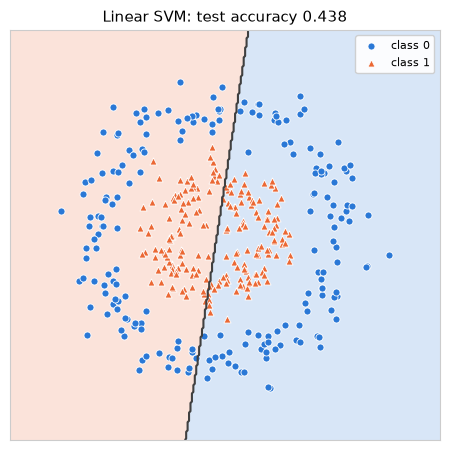

In [2]:
# PROVIDED
linear = make_pipeline(StandardScaler(), LinearSVC(max_iter=20000, random_state=0))
linear.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(4.6, 4.6))
plot_boundary(linear, X, y, ax, f'Linear SVM: test accuracy {linear.score(X_test, y_test):.3f}')
ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
plt.tight_layout(); plt.show()

**Q1.** The accuracy is what you would get by flipping a coin. Would training it for longer help?

*Your answer here.*

## 2. Bend the space, not the boundary

The two classes differ in their distance from the origin, so add that as a
feature. Below, `z` is $x_1^2 + x_2^2$.

In [1]:
# PROVIDED
z = (X ** 2).sum(axis=1)

fig, ax = plt.subplots(figsize=(6.4, 2.6))
for c in (0, 1):
    ax.scatter(z[y == c], np.full((y == c).sum(), c), label=f'class {c}')
ax.set_xlabel(r'$z = x_1^2 + x_2^2$')
ax.set_yticks([0, 1]); ax.set_ylabel('class')
ax.legend(fontsize=8, loc='center right')

plt.tight_layout(); plt.show()

NameError: name 'X' is not defined

In two dimensions the classes needed a circle. Along $z$ a single threshold
does it. The next cell fits a **linear** model on the squared features, then two
kernel models that never build those features at all.

In [4]:

results = [
    ('linear SVM, raw features',
     make_pipeline(StandardScaler(), LinearSVC(max_iter=20000, random_state=0)),
     X_train, X_test),
    ('linear SVM on [x1^2, x2^2]',
     make_pipeline(StandardScaler(), LinearSVC(max_iter=20000, random_state=0)),
     X_train ** 2, X_test ** 2),
    ('SVC(kernel="poly", degree=2)',
     make_pipeline(StandardScaler(), SVC(kernel='poly', degree=2, random_state=0)),
     X_train, X_test),
    ('SVC(kernel="rbf")',
     make_pipeline(StandardScaler(), SVC(kernel='rbf', gamma=1, random_state=0)),
     X_train, X_test),
]

print(f'{"model":32s}{"test accuracy":>14s}')
for name, model, Xa, Xb in results:
    model.fit(Xa, y_train)
    print(f'{name:32s}{model.score(Xb, y_test):14.4f}')

model                            test accuracy
linear SVM, raw features                0.4375
linear SVM on [x1^2, x2^2]              1.0000
SVC(kernel="poly", degree=2)            1.0000
SVC(kernel="rbf")                       1.0000


## 3. k nearest neighbors

No training, no weights. To classify a point, find the `k` closest training
points and take their majority vote.

The rest of the notebook uses `Xn`, the **noisier** version of the same
circles. A knob that controls flexibility only matters when there is noise
available to fit.

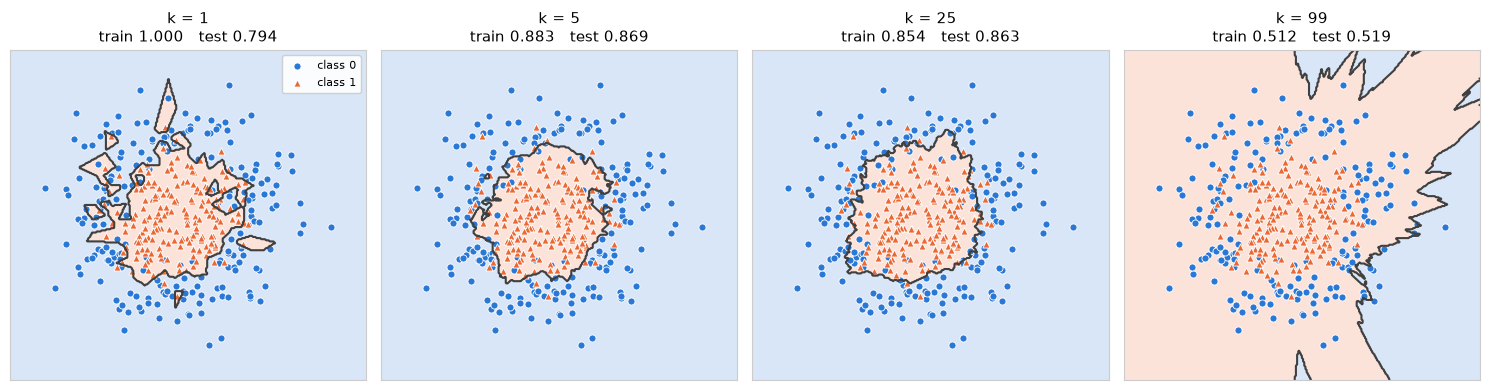

In [5]:
# PROVIDED
ks = [1, 5, 25, 99]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for k, ax in zip(ks, axes):
    knn = KNeighborsClassifier(n_neighbors=k).fit(Xn_train, yn_train)
    plot_boundary(knn, Xn, yn, ax,
                  f'k = {k}\ntrain {knn.score(Xn_train, yn_train):.3f}   '
                  f'test {knn.score(Xn_test, yn_test):.3f}')
axes[0].legend(loc='upper right', fontsize=8, framealpha=0.9)
plt.tight_layout(); plt.show()

## 4. The RBF kernel and `gamma`

`gamma` sets how far a single training point's influence reaches. Small `gamma`
means wide influence, large `gamma` means each point only speaks for its own
neighborhood.

In [ ]:
# PROVIDED
gammas = [0.1, 1, 100, 1000]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for g, ax in zip(gammas, axes):
    svm = make_pipeline(StandardScaler(), SVC(kernel='rbf', gamma=g, random_state=0))
    svm.fit(Xn_train, yn_train)
    plot_boundary(svm, Xn, yn, ax,
                  f'gamma = {g}\ntrain {svm.score(Xn_train, yn_train):.3f}   '
                  f'test {svm.score(Xn_test, yn_test):.3f}')
axes[0].legend(loc='upper right', fontsize=8, framealpha=0.9)
plt.tight_layout(); plt.show()

## Summary

Both models here produce curved boundaries, and both have one knob that trades
flexibility against stability.

| model | the knob | too flexible | too rigid |
|---|---|---|---|
| k nearest neighbors | `n_neighbors` | small `k` | large `k` |
| RBF SVM | `gamma` | large `gamma` | small `gamma` |
